## 0. Imports
Every library is imported once at the top, so anyone reading the notebook can see what it depends on.

In [1]:
%pip install pandas numpy nltk scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os                      
import re                      
import csv                     
from collections import Counter  

import numpy as np             
import pandas as pd            
import matplotlib.pyplot as plt  
import seaborn as sns          

import nltk                    
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split          
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer  
from sklearn.linear_model import LogisticRegression           
from sklearn.svm import LinearSVC                             
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")   

## 1. Download and load the dataset


In [3]:
DATA_DIR = r"C:\Users\Dell\Desktop\LLM-Practical-Portfolio\Lab-01-Machine-Learning\sentiment labelled sentences"
FILES = {
    "amazon": "amazon_cells_labelled.txt",
    "imdb":   "imdb_labelled.txt",
    "yelp":   "yelp_labelled.txt",
}

frames = []                                  
for source, filename in FILES.items():
    path = os.path.join(DATA_DIR, filename)
    part = pd.read_csv(
        path,
        sep="\t",                
        header=None,             
        names=["text", "label"], 
        quoting=csv.QUOTE_NONE,  
        encoding_errors="replace",  
    )
    part["source"] = source      
    frames.append(part)

df = pd.concat(frames, ignore_index=True)    
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (3000, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [4]:
print("Missing values:\n", df.isnull().sum(), "\n")
print("Duplicate sentences:", df.duplicated(subset="text").sum())


df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))
print("\nClass balance:\n", df["label"].value_counts())

Missing values:
 text      0
label     0
source    0
dtype: int64 

Duplicate sentences: 17
Rows after removing duplicates: 2983

Class balance:
 label
0    1493
1    1490
Name: count, dtype: int64


## 2. Text preprocessing


In [5]:
def clean_text(text):
    text = text.lower()                    
    text = re.sub(r"[’']", "", text)      
    text = re.sub(r"[^a-z\s]", " ", text)  
    text = re.sub(r"\s+", " ", text)       
    return text.strip()                    

df["clean_text"] = df["text"].apply(clean_text)   

empty_rows = (df["clean_text"] == "").sum()
print("Empty after cleaning:", empty_rows)
df = df[df["clean_text"] != ""].reset_index(drop=True)

Empty after cleaning: 1


In [6]:
pd.set_option("display.max_colwidth", 90)
df[["text", "clean_text"]].sample(6, random_state=1)

,text,clean_text
540,"sucked, most of the stuff does not work with my phone.",sucked most of the stuff does not work with my phone
2353,Would come back again if I had a sushi craving while in Vegas.,would come back again if i had a sushi craving while in vegas
829,I don't like this Nokia either.,i dont like this nokia either
2583,It'll be a regular stop on my trips to Phoenix!,itll be a regular stop on my trips to phoenix
784,I own 2 of these cases and would order another.,i own of these cases and would order another
1149,THERE IS NO PLOT OR STORYLINE!!,there is no plot or storyline


## 3. Explore the text data

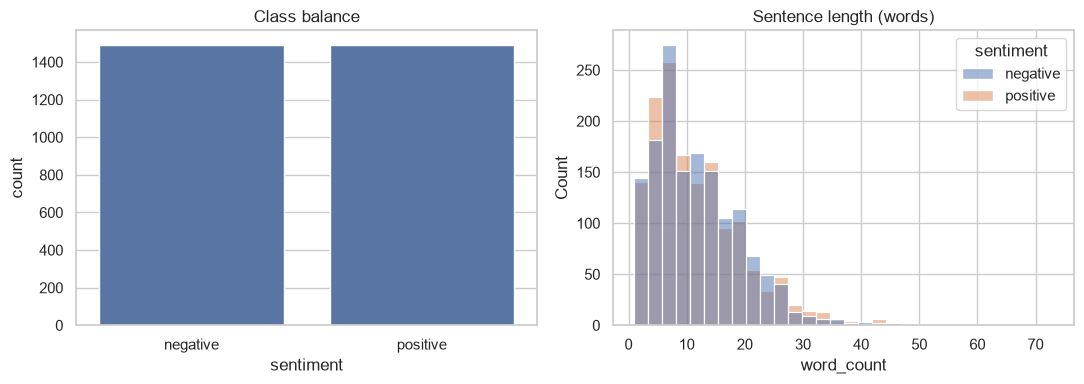

            count  mean  std  min  25%   50%   75%   max
sentiment                                               
negative   1493.0  11.9  7.6  1.0  6.0  10.0  16.0  57.0
positive   1489.0  11.8  8.2  1.0  6.0  10.0  16.0  73.0


In [7]:
df["sentiment"] = df["label"].map({0: "negative", 1: "positive"})   
df["word_count"] = df["clean_text"].str.split().str.len()           

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="sentiment", ax=axes[0])
axes[0].set_title("Class balance")
sns.histplot(data=df, x="word_count", hue="sentiment", bins=30, ax=axes[1])
axes[1].set_title("Sentence length (words)")
plt.tight_layout()
plt.show()

print(df.groupby("sentiment")["word_count"].describe().round(1))

In [8]:
print("POSITIVE examples")
for s in df[df["label"] == 1]["text"].sample(5, random_state=3):
    print("  +", s)

print("\nNEGATIVE examples")
for s in df[df["label"] == 0]["text"].sample(5, random_state=3):
    print("  -", s)

POSITIVE examples
  + It is so small and you don't even realize that it is there after a while of getting used to it.
  + Magical Help.
  + I am very impressed with the job that Motorola did on the sturdiness of this phone.
  + Great charger.
  + Great Product.

NEGATIVE examples
  - Items stated as included from the description ARE NOT INCLUDED.
  - Both films are terrible, but to the credit of the 1986 version, it was watchable.  
  - Disapointing Results.
  - If you like a loud buzzing to override all your conversations, then this phone is for you!
  - The one down note is the ventilation could use some upgrading.


[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>


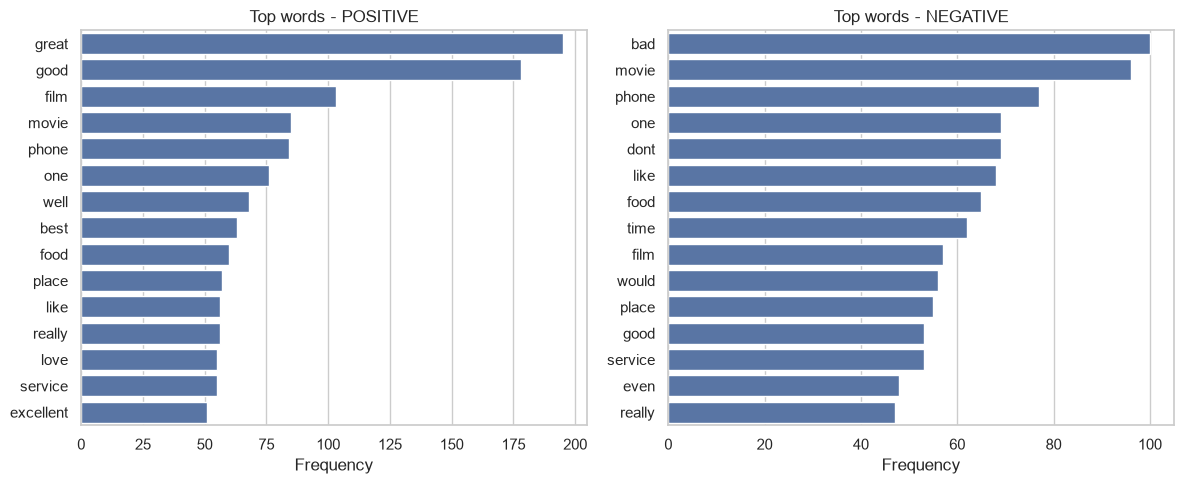

Only in positive top list: ['best', 'excellent', 'great', 'love', 'well']
Only in negative top list: ['bad', 'dont', 'even', 'time', 'would']


In [9]:
nltk.download("stopwords", quiet=True)   
try:
    stop_words = set(stopwords.words("english"))
except LookupError:                       
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    stop_words = set(ENGLISH_STOP_WORDS)

def top_words(texts, n=15):
    counter = Counter()
    for t in texts:
        counter.update(w for w in t.split() if w not in stop_words and len(w) > 2)
    return counter.most_common(n)

top_pos = top_words(df[df["label"] == 1]["clean_text"])
top_neg = top_words(df[df["label"] == 0]["clean_text"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title in [(axes[0], top_pos, "Top words - POSITIVE"), (axes[1], top_neg, "Top words - NEGATIVE")]:
    words, counts = zip(*data)              
    sns.barplot(x=list(counts), y=list(words), ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

pos_only = {w for w, _ in top_pos} - {w for w, _ in top_neg}
neg_only = {w for w, _ in top_neg} - {w for w, _ in top_pos}
print("Only in positive top list:", sorted(pos_only))
print("Only in negative top list:", sorted(neg_only))

## 4. Split the dataset


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],      
    df["label"],           
    test_size=0.2,        
    random_state=42,       
    stratify=df["label"], 
)
print("Training sentences:", len(X_train), "| Test sentences:", len(X_test))

Training sentences: 2385 | Test sentences: 597


## 5. Bag-of-Words

In [11]:
bow = CountVectorizer()                       
X_train_bow = bow.fit_transform(X_train)     
X_test_bow = bow.transform(X_test)            

print("Vocabulary size:", len(bow.vocabulary_))
print("Training matrix shape (sentences x words):", X_train_bow.shape)
print("Share of cells that are zero: {:.2%}".format(1 - X_train_bow.nnz / np.prod(X_train_bow.shape)))


i = 0
print("\nSentence:", X_train.iloc[i])
words_in_sentence = [(w, int(X_train_bow[i, idx])) for w, idx in bow.vocabulary_.items() if X_train_bow[i, idx] > 0]
print("Its BOW counts:", words_in_sentence)

Vocabulary size: 4460
Training matrix shape (sentences x words): (2385, 4460)
Share of cells that are zero: 99.76%

Sentence: yes its that bad
Its BOW counts: [('yes', 1), ('its', 1), ('that', 1), ('bad', 1)]


## 6. Train the models


In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),  
    "Linear SVM": LinearSVC(),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_bow, y_train)              
    predictions[name] = model.predict(X_test_bow)  
    print("Trained:", name)

Trained: Logistic Regression
Trained: Linear SVM


## 7. Evaluate

In [13]:
rows = {}
for name, pred in predictions.items():
    rows[name] = {
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),   
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
    }
results = pd.DataFrame(rows).T.round(3)
display(results)

best_name = results["F1"].idxmax()    
best_model = models[best_name]
print("Best model by F1:", best_name)

,Accuracy,Precision,Recall,F1
Logistic Regression,0.796,0.803,0.782,0.793
Linear SVM,0.797,0.800,0.792,0.796


Best model by F1: Linear SVM


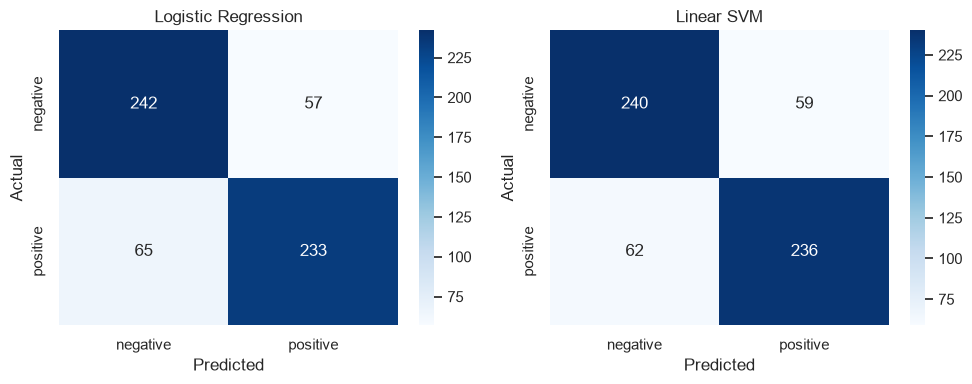

              precision    recall  f1-score   support

    negative       0.79      0.80      0.80       299
    positive       0.80      0.79      0.80       298

    accuracy                           0.80       597
   macro avg       0.80      0.80      0.80       597
weighted avg       0.80      0.80      0.80       597



In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(y_test, predictions[best_name], target_names=["negative", "positive"]))

In [15]:
errors = pd.DataFrame({
    "text": df.loc[X_test.index, "text"],        
    "actual": y_test,
    "predicted": predictions[best_name],
})
errors = errors[errors["actual"] != errors["predicted"]]
print("Misclassified:", len(errors), "of", len(y_test))
errors.sample(min(8, len(errors)), random_state=1)

Misclassified: 121 of 597


,text,actual,predicted
1022,This is the kind of money that is wasted properly.,1,0
1877,Now this is a movie I really dislike.,0,1
1452,The death row scenes were entirely unmoving.,0,1
2021,The only redeeming quality of the restaurant was that it was very inexpensive.,1,0
1836,Now imagine that every single one of those decisions was made wrong.,0,1
1956,Enough can not be said of the remarkable animation in this film.,1,0
2809,Won't ever go here again.,0,1
1758,"All the actors give a wonderful performance, especially Jennifer Rubin as Jamie Harris...",1,0


## 8. Test with new sentences

In [16]:
def predict_sentiment(sentence, model=best_model, vectorizer=bow):
    cleaned = clean_text(sentence)               
    features = vectorizer.transform([cleaned])   
    label = model.predict(features)[0]
    return "positive" if label == 1 else "negative"

new_sentences = [
    "The battery life is amazing and the screen is gorgeous.",
    "Worst customer service I have ever experienced.",
    "The food was not good at all.",              
    "I did not hate it.",                          
    "Oh great, another delay. Just perfect.",      
    "The film was fine I suppose.",                
]
for s in new_sentences:
    print(f"{predict_sentiment(s):>8}  <-  {s}")

positive  <-  The battery life is amazing and the screen is gorgeous.
negative  <-  Worst customer service I have ever experienced.
negative  <-  The food was not good at all.
negative  <-  I did not hate it.
positive  <-  Oh great, another delay. Just perfect.
positive  <-  The film was fine I suppose.


In [17]:
lr = models["Logistic Regression"]
for s in new_sentences:
    p_pos = lr.predict_proba(bow.transform([clean_text(s)]))[0][1]
    print(f"P(positive) = {p_pos:.2f}  <-  {s}")

P(positive) = 0.93  <-  The battery life is amazing and the screen is gorgeous.
P(positive) = 0.05  <-  Worst customer service I have ever experienced.
P(positive) = 0.17  <-  The food was not good at all.
P(positive) = 0.08  <-  I did not hate it.
P(positive) = 0.97  <-  Oh great, another delay. Just perfect.
P(positive) = 0.84  <-  The film was fine I suppose.


## 9. Does a better representation help?

In [18]:
variants = {
    "BOW (unigrams)":        CountVectorizer(),
    "BOW (uni+bigrams)":     CountVectorizer(ngram_range=(1, 2)),
    "TF-IDF (unigrams)":     TfidfVectorizer(),
    "TF-IDF (uni+bigrams)":  TfidfVectorizer(ngram_range=(1, 2)),
}
bonus = {}
for name, vec in variants.items():
    Xtr = vec.fit_transform(X_train)     
    Xte = vec.transform(X_test)
    clf = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    pred = clf.predict(Xte)
    bonus[name] = {"Accuracy": accuracy_score(y_test, pred), "F1": f1_score(y_test, pred)}
display(pd.DataFrame(bonus).T.round(3))

,Accuracy,F1
BOW (unigrams),0.796,0.793
BOW (uni+bigrams),0.806,0.805
TF-IDF (unigrams),0.787,0.785
TF-IDF (uni+bigrams),0.791,0.791


## 10. Observations 
Model comparison

Logistic Regression achieved 79.6% accuracy and an F1 score of 79.3%. The Linear SVM achieved 79.7% accuracy and an F1 score of 79.6%. The SVM's advantage was only 0.1 percentage points in accuracy and 0.3 points in F1, so the difference is very small on this test set. The test set was balanced (299 negative, 298 positive), and all results come from a single 80/20 split. I did not run a statistical significance test, so I can't say either model is truly better. 

Feature comparison

Using Logistic Regression, Bag-of-Words with unigrams and bigrams performed best, reaching 80.6% accuracy and an F1 score of 80.5%, compared with 79.6% for unigrams alone. This is only about a one-point gain, but bigrams may have helped the model pick up short phrases such as "not good". TF-IDF did not help: it scored 78.7% with unigrams and 79.1% with bigrams. A possible reason is that the sentences are short, so there was little for TF-IDF to re-weight, though I did not test this.

Positive and negative sentences

The words appearing only in the positive top list were best, excellent, great, love and well. The words appearing only in the negative top list were bad, dont, even, time and would. The positive list contains clearly favourable words, while the negative list contains bad and dont alongside more general words. Frequent words give clues about sentiment, but a word's frequency does not show its meaning in context.

Misclassified sentences

The best model by F1 (Linear SVM) misclassified 121 of 597 test sentences, about 20.3%. The errors included negation, mixed opinions and unusual or context-dependent wording. For example, "Enough can not be said of the remarkable animation in this film" was predicted negative, probably because of "not". "Won't ever go here again" was predicted positive. One possible cause is that my cleaning step turns "won't" into "wont", which may be a rare word in the training data [check how often "wont" appears before keeping this explanation]. Some sentences, such as "Now imagine that every single one of those decisions was made wrong", have almost no sentiment words, so a word-count model has little to work with.

Testing on new sentences

My own test sentences showed further limits. "Oh great, another delay. Just perfect." is sarcastic but got P(positive) = 0.97 from Logistic Regression, because the model only sees the words "great" and "perfect". "I did not hate it" got P(positive) = 0.08, so the model reacted to "hate" and ignored "not". "The film was fine I suppose" got 0.84, even though it is closer to neutral, and since the dataset only has positive and negative labels, the model has no way to say neutral.

Limitations

Bag-of-Words represents text using word counts and does not keep word order, which is why negation, sarcasm, idioms and mixed opinions cause errors. Transformer models use attention to represent each token in context, which can help with these cases. They can still make mistakes, so their performance would need to be measured on this task as well.